# BurnInWatch — Raw Signal Extraction & Canonical Dataset v1

We have now learned something important from the first two notebooks:

- The SMU CSV files **do not contain a header row**. The first numeric measurement was incorrectly interpreted as the column name by `pandas.read_csv()` when `header=None` was not specified.
- The aging MAT files contain structured MATLAB records. Device files expose `measurement.transient`, `measurement.steadyState`, and `measurement.pwmTempControllerState`.
- The main DC aging experiment contains synchronized flat arrays such as `TIME`, `GATE_VOLTAGE`, `COLLECTOR_VOLTAGE`, `HEAT_SINK_TEMP`, `GATE_CURRENT`, `COLLECTOR_CURRENT`, and `PACKAGE_TEMP`.

This notebook fixes the CSV interpretation and carefully inspects/exports the structured aging records.

**No ML model is trained here. No synthetic observations are created.**

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

DATA_ROOT = Path("dataset/Data").resolve()
OUT_DIR = Path("processed")
OUT_DIR.mkdir(exist_ok=True)

print("DATA_ROOT:", DATA_ROOT)

DATA_ROOT: C:\Users\Abhishek Kuma\Desktop\BurnInWatch\dataset\Data


## 1. Correctly read the SMU CSV files

The earlier result showed columns such as `5.452415E+2` and `1.042480E-5`. Those are clearly **measurement values**, not meaningful column names.

Therefore the CSVs should be read with:

```python
pd.read_csv(path, header=None)
```

We will preserve the original two numerical columns as `measurement_1` and `measurement_2` until the NASA documentation tells us their exact engineering meanings.

In [2]:
# ============================================================
# 1A. READ ALL SMU CSVs WITHOUT A HEADER
# ============================================================

csv_files = sorted(DATA_ROOT.rglob("*.csv"))

smu_rows = []

for path in csv_files:
    try:
        df = pd.read_csv(path, header=None)

        # Keep only files with the expected 2-column numerical structure.
        if df.shape[1] != 2:
            print("Unexpected number of columns:", path.relative_to(DATA_ROOT), df.shape)
            continue

        df.columns = ["measurement_1", "measurement_2"]

        # Convert safely to numeric.
        df["measurement_1"] = pd.to_numeric(df["measurement_1"], errors="coerce")
        df["measurement_2"] = pd.to_numeric(df["measurement_2"], errors="coerce")

        # Metadata from folder/file path.
        rel = path.relative_to(DATA_ROOT)
        parts = rel.parts

        device_family = parts[2] if len(parts) >= 3 else "unknown"
        part_id = parts[3] if len(parts) >= 4 else "unknown"
        test_type = path.stem

        tmp = df.copy()
        tmp["device_family"] = device_family
        tmp["part_id"] = part_id
        tmp["test_type"] = test_type
        tmp["source_file"] = str(rel)

        smu_rows.append(tmp)

    except Exception as e:
        print("FAILED:", path.relative_to(DATA_ROOT), repr(e))

smu_raw = pd.concat(smu_rows, ignore_index=True)

print("SMU rows:", len(smu_raw))
print("Columns:", list(smu_raw.columns))
display(smu_raw.head(10))

smu_raw.to_csv(OUT_DIR / "smu_raw_no_header.csv", index=False)
print("Saved:", OUT_DIR / "smu_raw_no_header.csv")

SMU rows: 24000
Columns: ['measurement_1', 'measurement_2', 'device_family', 'part_id', 'test_type', 'source_file']


,measurement_1,measurement_2,device_family,part_id,test_type,source_file
0,545.2415,0.000010,Part 11,Breakdown.csv,Breakdown,SMU Data for new devices\IGBT-IRG4BC30K\Part 1...
1,550.5257,0.000004,Part 11,Breakdown.csv,Breakdown,SMU Data for new devices\IGBT-IRG4BC30K\Part 1...
2,551.0267,0.000004,Part 11,Breakdown.csv,Breakdown,SMU Data for new devices\IGBT-IRG4BC30K\Part 1...
3,551.5286,0.000004,Part 11,Breakdown.csv,Breakdown,SMU Data for new devices\IGBT-IRG4BC30K\Part 1...
4,552.0283,0.000004,Part 11,Breakdown.csv,Breakdown,SMU Data for new devices\IGBT-IRG4BC30K\Part 1...
5,552.5309,0.000004,Part 11,Breakdown.csv,Breakdown,SMU Data for new devices\IGBT-IRG4BC30K\Part 1...
6,553.0318,0.000004,Part 11,Breakdown.csv,Breakdown,SMU Data for new devices\IGBT-IRG4BC30K\Part 1...
7,553.5347,0.000004,Part 11,Breakdown.csv,Breakdown,SMU Data for new devices\IGBT-IRG4BC30K\Part 1...
8,554.0364,0.000004,Part 11,Breakdown.csv,Breakdown,SMU Data for new devices\IGBT-IRG4BC30K\Part 1...
9,554.5375,0.000004,Part 11,Breakdown.csv,Breakdown,SMU Data for new devices\IGBT-IRG4BC30K\Part 1...


Saved: processed\smu_raw_no_header.csv


In [3]:
# ============================================================
# 1B. SMU SUMMARY BY DEVICE AND TEST
# ============================================================

smu_summary = (
    smu_raw
    .groupby(["device_family", "part_id", "test_type"], dropna=False)
    .agg(
        rows=("measurement_1", "size"),
        m1_min=("measurement_1", "min"),
        m1_max=("measurement_1", "max"),
        m1_mean=("measurement_1", "mean"),
        m2_min=("measurement_2", "min"),
        m2_max=("measurement_2", "max"),
        m2_mean=("measurement_2", "mean"),
    )
    .reset_index()
)

display(smu_summary.head(20))
smu_summary.to_csv(OUT_DIR / "smu_summary.csv", index=False)

,device_family,part_id,test_type,rows,m1_min,m1_max,m1_mean,m2_min,m2_max,m2_mean
0,Part 1,Breakdown.csv,Breakdown,200,100.008400,114.270100,109.159839,-6.519411e-10,0.000250,0.000069
1,Part 1,LeakageIV.csv,LeakageIV,200,1.009408,114.563300,60.347505,-1.063469e-08,0.000024,0.000001
2,Part 1,Turn On.csv,Turn On,200,2.000284,3.371288,3.134007,-5.812811e-11,0.000300,0.000204
3,Part 10,Breakdown.csv,Breakdown,200,100.010700,114.373600,109.115666,-4.044946e-09,0.000250,0.000069
4,Part 10,LeakageIV.csv,LeakageIV,200,1.008906,114.597900,60.369047,-5.063135e-09,0.000025,0.000001
5,Part 10,Turn On.csv,Turn On,200,2.000336,3.385607,3.143262,1.629450e-10,0.000300,0.000203
6,Part 11,Breakdown.csv,Breakdown,400,100.011100,650.039400,354.584681,1.993393e-09,0.000250,0.000036
7,Part 11,LeakageIV.csv,LeakageIV,400,1.007554,600.048800,180.442530,-4.668137e-09,0.000024,0.000001
8,Part 11,Turn On.csv,Turn On,400,2.000314,5.059252,3.514295,-2.372367e-09,0.000300,0.000136
9,Part 12,Breakdown.csv,Breakdown,400,100.012000,650.038600,354.579354,1.862564e-09,0.000250,0.000037


## 2. Inspect the structured `measurement` records

Before flattening the device aging MAT files, we need to see the fields of an actual `steadyState` record.

This prevents us from inventing names or losing nested information.

In [4]:
# ============================================================
# 2A. SHOW FIELDS OF THE FIRST DEVICE STEADY-STATE RECORD
# ============================================================

device_mat_files = sorted(
    p for p in DATA_ROOT.rglob("*.mat")
    if "Aging Data" in str(p)
)

print("Device aging files:", len(device_mat_files))

for path in device_mat_files[:1]:
    print("\nFILE:", path.relative_to(DATA_ROOT))

    data = loadmat(path, squeeze_me=True, struct_as_record=False)
    measurement = data["measurement"]

    print("measurement fields:", measurement._fieldnames)

    steady = measurement.steadyState
    print("steadyState length:", len(steady))

    first = steady[0]
    print("\nFIRST steadyState record type:", type(first))
    print("FIRST record fields:")

    for field in first._fieldnames:
        value = getattr(first, field)
        print(
            f"  {field:40s}",
            f"type={type(value).__name__:<15s}",
            f"shape={getattr(value, 'shape', None)}",
            f"dtype={getattr(value, 'dtype', None)}",
            f"value={repr(value)[:150]}"
        )

Device aging files: 10

FILE: Thermal Overstress Aging with Square Signal at gate and SMU data\Aging Data\Device 2\Device2  1.mat
measurement fields: ['pwmTempControllerState', 'transient', 'steadyState']
steadyState length: 10978

FIRST steadyState record type: <class 'scipy.io.matlab._mio5_params.mat_struct'>
FIRST record fields:
  date                                     type=str             shape=None dtype=None value='12/31/1903 4:00:00 PM'
  timeEpoch                                type=int             shape=None dtype=None value=0
  timeDomain                               type=mat_struct      shape=None dtype=None value=<scipy.io.matlab._mio5_params.mat_struct object at 0x0000021D7F8AD650>


In [5]:
# ============================================================
# 2B. FIND ALL FIELDS USED IN STEADYSTATE RECORDS
# ============================================================

field_map = {}

for path in device_mat_files:
    try:
        data = loadmat(path, squeeze_me=True, struct_as_record=False)
        measurement = data["measurement"]

        steady = getattr(measurement, "steadyState", None)
        if steady is None:
            continue

        for record in steady:
            if not hasattr(record, "_fieldnames"):
                continue

            for field in record._fieldnames:
                value = getattr(record, field)
                field_map.setdefault(field, set()).add(type(value).__name__)

    except Exception as e:
        print("FAILED:", path.relative_to(DATA_ROOT), repr(e))

field_table = pd.DataFrame([
    {
        "field": field,
        "python_types": ", ".join(sorted(types))
    }
    for field, types in sorted(field_map.items())
])

display(field_table)
field_table.to_csv(OUT_DIR / "aging_steady_state_field_inventory.csv", index=False)

,field,python_types
0,date,str
1,timeDomain,mat_struct
2,timeEpoch,"float, int"


## 3. Flatten scalar/vector fields from `steadyState`

We only flatten fields that are simple numeric scalars or short numeric arrays.

Nested MATLAB structures are preserved for later inspection rather than being silently discarded.

Each output row represents **one recorded steady-state event** from one device file.

In [6]:
# ============================================================
# 3A. SAFE VALUE CONVERSION
# ============================================================

def scalar_or_numeric(value):
    """Return a scalar/1-D numeric value when possible, otherwise None."""
    try:
        arr = np.asarray(value)

        if np.issubdtype(arr.dtype, np.number):
            arr = np.squeeze(arr)

            if arr.ndim == 0:
                return float(arr)

            if arr.ndim == 1 and arr.size <= 20:
                return arr.astype(float).tolist()

    except Exception:
        pass

    return None


def record_to_dict(record):
    result = {}

    if not hasattr(record, "_fieldnames"):
        return result

    for field in record._fieldnames:
        value = getattr(record, field)
        converted = scalar_or_numeric(value)

        if converted is not None:
            result[field] = converted

    return result

In [7]:
# ============================================================
# 3B. EXTRACT STEADY-STATE RECORDS
# ============================================================

aging_records = []

for path in device_mat_files:
    rel = path.relative_to(DATA_ROOT)

    # Device ID from folder name, e.g. Device 2
    device_id = "unknown"
    for part in rel.parts:
        if part.lower().startswith("device "):
            device_id = part.replace(" ", "_")

    # Experiment/file identity
    experiment_file = path.stem

    try:
        data = loadmat(path, squeeze_me=True, struct_as_record=False)
        measurement = data["measurement"]

        steady = getattr(measurement, "steadyState", None)

        if steady is None:
            continue

        for event_idx, record in enumerate(steady):
            row = record_to_dict(record)

            if row:
                row["device_id"] = device_id
                row["event_index"] = event_idx
                row["source_file"] = str(rel)
                row["source_type"] = "steadyState"

                aging_records.append(row)

    except Exception as e:
        print("FAILED:", rel, repr(e))

aging_steady = pd.DataFrame(aging_records)

print("Extracted steady-state records:", len(aging_steady))
print("Columns:", list(aging_steady.columns))
display(aging_steady.head(10))

aging_steady.to_csv(
    OUT_DIR / "aging_steady_state_raw.csv",
    index=False
)

print("Saved:", OUT_DIR / "aging_steady_state_raw.csv")

Extracted steady-state records: 68769
Columns: ['timeEpoch', 'device_id', 'event_index', 'source_file', 'source_type']


,timeEpoch,device_id,event_index,source_file,source_type
0,0.000000e+00,Device_2,0,Thermal Overstress Aging with Square Signal at...,steadyState
1,3.312986e+09,Device_2,1,Thermal Overstress Aging with Square Signal at...,steadyState
2,3.312986e+09,Device_2,2,Thermal Overstress Aging with Square Signal at...,steadyState
3,3.312986e+09,Device_2,3,Thermal Overstress Aging with Square Signal at...,steadyState
4,3.312986e+09,Device_2,4,Thermal Overstress Aging with Square Signal at...,steadyState
5,3.312986e+09,Device_2,5,Thermal Overstress Aging with Square Signal at...,steadyState
6,3.312986e+09,Device_2,6,Thermal Overstress Aging with Square Signal at...,steadyState
7,3.312986e+09,Device_2,7,Thermal Overstress Aging with Square Signal at...,steadyState
8,3.312986e+09,Device_2,8,Thermal Overstress Aging with Square Signal at...,steadyState
9,3.312986e+09,Device_2,9,Thermal Overstress Aging with Square Signal at...,steadyState


Saved: processed\aging_steady_state_raw.csv


In [8]:
# ============================================================
# 3C. DATA COMPLETENESS
# ============================================================

if not aging_steady.empty:
    print("Records by device:")
    display(
        aging_steady.groupby("device_id")
        .agg(
            records=("event_index", "size"),
            first_event=("event_index", "min"),
            last_event=("event_index", "max")
        )
        .reset_index()
    )

    print("\nMissing values:")
    missing = (
        aging_steady.isna()
        .mean()
        .sort_values(ascending=False)
        .to_frame("missing_fraction")
    )
    display(missing)

Records by device:


,device_id,records,first_event,last_event
0,Device_2,17529,0,10977
1,Device_3,15188,0,9836
2,Device_4,25379,0,14607
3,Device_5,10673,0,10510



Missing values:


,missing_fraction
timeEpoch,0.0
device_id,0.0
event_index,0.0
source_file,0.0
source_type,0.0


## 4. Inspect the flat DC aging experiment

This experiment already contains synchronized arrays. We will convert them into a long-form CSV with one row per measurement timestamp.

This is a raw extraction, not feature engineering.

In [9]:
# ============================================================
# 4A. EXTRACT FLAT DC-GATE AGING DATA
# ============================================================

dc_files = sorted(
    p for p in DATA_ROOT.rglob("*.mat")
    if "Thermal Overstress Aging with DC at gate" in str(p)
)

for path in dc_files:
    print("DC file:", path.relative_to(DATA_ROOT))

dc_path = dc_files[0]

dc = loadmat(dc_path, squeeze_me=True, struct_as_record=False)

required = [
    "TIME",
    "GATE_VOLTAGE",
    "COLLECTOR_VOLTAGE",
    "HEAT_SINK_TEMP",
    "GATE_CURRENT",
    "COLLECTOR_CURRENT",
    "PACKAGE_TEMP",
]

print("Available keys:")
print([k for k in dc.keys() if not k.startswith("__")])

for key in required:
    arr = np.asarray(dc[key]).squeeze()
    print(f"{key:25s} shape={arr.shape} dtype={arr.dtype}")

DC file: Thermal Overstress Aging with DC at gate\20080429T135531.mat
Available keys:
['index', 'x', 'gate_current', 'time', 'collector_current', 'heat_sink', 'package_temperture', 'gate_voltage', 'collector_voltage', 'GATE_VOLTAGE', 'COLLECTOR_VOLTAGE', 'HEAT_SINK_TEMP', 'GATE_CURRENT', 'COLLECTOR_CURRENT', 'TIME', 'PACKAGE_TEMP', 'current_time', 'current_date', 'data_path', 'comment']
TIME                      shape=(301680,) dtype=float64
GATE_VOLTAGE              shape=(301680,) dtype=float64
COLLECTOR_VOLTAGE         shape=(301680,) dtype=float64
HEAT_SINK_TEMP            shape=(301680,) dtype=float64
GATE_CURRENT              shape=(301680,) dtype=float64
COLLECTOR_CURRENT         shape=(301680,) dtype=float64
PACKAGE_TEMP              shape=(301680,) dtype=float64


In [10]:
# ============================================================
# 4B. CREATE RAW DC-GATE TABLE
# ============================================================

dc_raw = pd.DataFrame({
    "time_raw": np.asarray(dc["TIME"]).squeeze(),
    "gate_voltage": np.asarray(dc["GATE_VOLTAGE"]).squeeze(),
    "collector_voltage": np.asarray(dc["COLLECTOR_VOLTAGE"]).squeeze(),
    "heat_sink_temp": np.asarray(dc["HEAT_SINK_TEMP"]).squeeze(),
    "gate_current": np.asarray(dc["GATE_CURRENT"]).squeeze(),
    "collector_current": np.asarray(dc["COLLECTOR_CURRENT"]).squeeze(),
    "package_temp": np.asarray(dc["PACKAGE_TEMP"]).squeeze(),
})

dc_raw["device_id"] = "DC_experiment"
dc_raw["sample_index"] = np.arange(len(dc_raw))
dc_raw["source_file"] = str(dc_path.relative_to(DATA_ROOT))

print("DC raw shape:", dc_raw.shape)
display(dc_raw.head())
display(dc_raw.describe().T)

dc_raw.to_csv(OUT_DIR / "dc_aging_raw.csv", index=False)
print("Saved:", OUT_DIR / "dc_aging_raw.csv")

DC raw shape: (301680, 10)


,time_raw,gate_voltage,collector_voltage,heat_sink_temp,gate_current,collector_current,package_temp,device_id,sample_index,source_file
0,3.292332e+09,0.135017,9.988193,-0.574011,-0.000224,-0.059492,58.544919,DC_experiment,0,Thermal Overstress Aging with DC at gate\20080...
1,3.292332e+09,1.446317,5.762021,-0.136453,0.005599,1.867384,58.382861,DC_experiment,1,Thermal Overstress Aging with DC at gate\20080...
2,3.292332e+09,2.707949,5.392024,0.592810,0.009967,7.143197,58.771801,DC_experiment,2,Thermal Overstress Aging with DC at gate\20080...
3,3.292332e+09,2.681923,6.008940,0.527987,0.009984,7.328754,58.852830,DC_experiment,3,Thermal Overstress Aging with DC at gate\20080...
4,3.292332e+09,2.680866,5.985234,0.479369,0.009970,7.546723,58.788007,DC_experiment,4,Thermal Overstress Aging with DC at gate\20080...


,count,mean,std,min,25%,50%,75%,max
time_raw,301680.0,3.292340e+09,4354.382947,3.292332e+09,3.292336e+09,3.292340e+09,3.292344e+09,3.292347e+09
gate_voltage,301680.0,1.355372e+00,1.332901,-8.474687e-02,6.842110e-03,2.147162e+00,2.683394e+00,2.729620e+00
collector_voltage,301680.0,5.728200e+00,3.980169,1.583185e+00,1.655807e+00,2.782892e+00,9.763308e+00,9.988193e+00
heat_sink_temp,301680.0,2.140512e-01,0.352693,-9.791573e-01,-6.806378e-03,3.335164e-01,4.793691e-01,1.046574e+00
gate_current,301680.0,5.149091e-03,0.004837,-2.235382e-04,2.465867e-04,9.893249e-03,9.953325e-03,1.126760e-02
collector_current,301680.0,4.162555e+00,3.768221,-6.192254e-02,3.602398e-01,7.889476e+00,7.902441e+00,9.791234e+00
package_temp,301680.0,2.687947e+02,7.769173,5.838286e+01,2.672277e+02,2.690589e+02,2.708254e+02,3.051656e+02
sample_index,301680.0,1.508395e+05,87087.658942,0.000000e+00,7.541975e+04,1.508395e+05,2.262592e+05,3.016790e+05


Saved: processed\dc_aging_raw.csv


In [11]:
# ============================================================
# 5. BASIC TIME CHECK
# ============================================================

time = pd.to_numeric(dc_raw["time_raw"], errors="coerce")

print("Time min:", time.min())
print("Time max:", time.max())

dt = time.diff()

print("\nTime difference statistics:")
display(dt.describe())

print("\nNon-positive time differences:", int((dt.dropna() <= 0).sum()))
print("Missing time values:", int(time.isna().sum()))

Time min: 3292332244.122931
Time max: 3292347328.0729313

Time difference statistics:


count    3.016790e+05
mean     5.000000e-02
std      2.336017e-07
min      4.999971e-02
25%      4.999971e-02
50%      5.000019e-02
75%      5.000019e-02
max      5.000019e-02
Name: time_raw, dtype: float64


Non-positive time differences: 0
Missing time values: 0


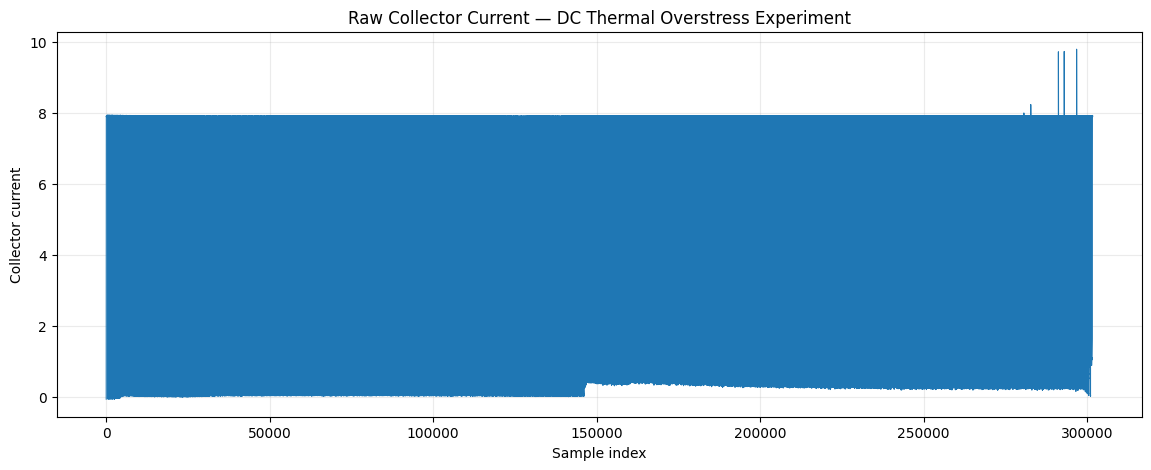

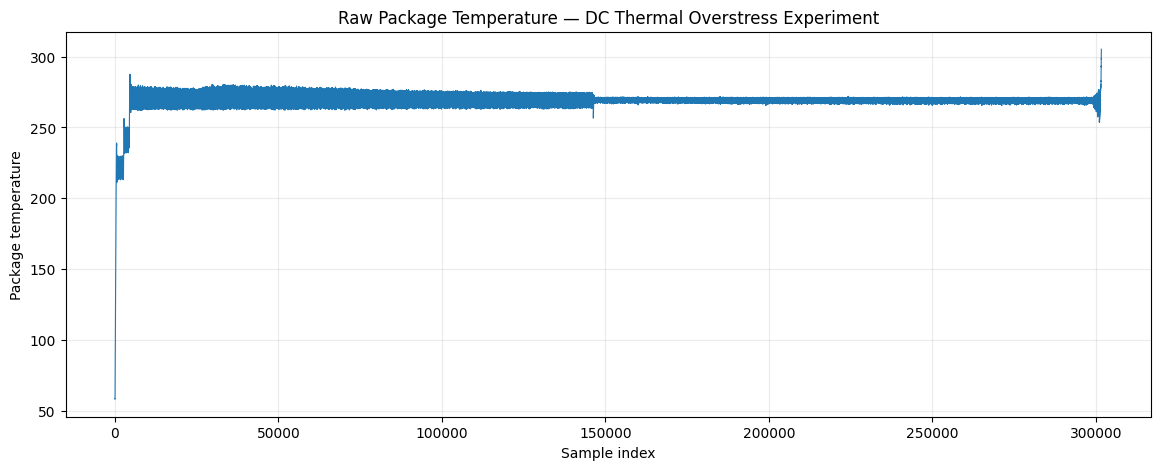

In [12]:
# ============================================================
# 6. BASIC VISUALIZATION OF RAW AGING SIGNALS
# ============================================================

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(dc_raw["sample_index"], dc_raw["collector_current"], linewidth=0.8)
ax.set_title("Raw Collector Current — DC Thermal Overstress Experiment")
ax.set_xlabel("Sample index")
ax.set_ylabel("Collector current")
ax.grid(alpha=0.25)
plt.show()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(dc_raw["sample_index"], dc_raw["package_temp"], linewidth=0.8)
ax.set_title("Raw Package Temperature — DC Thermal Overstress Experiment")
ax.set_xlabel("Sample index")
ax.set_ylabel("Package temperature")
ax.grid(alpha=0.25)
plt.show()

# Stop here

At this stage we will have:

- corrected SMU raw CSV data
- an inventory of the SMU test measurements
- the actual fields inside device `steadyState` records
- a canonical table of extracted steady-state events
- a canonical raw table for the large DC aging experiment
- basic time and signal diagnostics

**Do not normalize, impute, synthesize anomalies, or train an anomaly detector yet.**

The next step will be deciding which measurements can be combined into a defensible BurnInWatch feature space.